# Wolf–elk model playground

Edit settings and model functions, then run the notebook from top to bottom. It compares normal, farmer, hunter, and combined scenarios across several starting populations. Plots display in the notebook and are not saved to disk.

Populations are ordered `(elk, wolves)`. Parameters are illustrative, not calibrated.

## Imports and settings

Change the parameter values, introduction schedule, time range, or initial populations here.

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from repo_model_snapshot import beddington_deangelis


# ---------------------------------------------------------------------------
# Edit these settings
# ---------------------------------------------------------------------------

# Norman Beddington-DeAngelis parameters (illustrative, not calibrated).
PARAMETERS = {
    "r_E": 0.40,       # elk growth rate
    "K": 1200.0,       # elk carrying capacity without farmers
    "alpha_FE": 10.0,  # carrying-capacity reduction per farmer
    "a": 0.001,        # wolf predation rate
    "h": 1.0,          # handling time in the Beddington-DeAngelis response
    "c": 0.001,        # wolf interference in the Beddington-DeAngelis response
    "eta": 0.25,       # conversion of elk consumed into wolf growth
    "d_W": 0.08,       # natural wolf death rate
    "c_HE": 0.003,     # elk loss per hunter
    "c_FW": 0.0009,     # wolf loss per farmer
}

MAX_FARMERS = 40.0
MAX_HUNTERS = 25.0
INTRODUCTION_START = 10.0
INTRODUCTION_DURATION = 35.0
INTRODUCTION_SHAPE = "smoothstep"  # linear, exponential, or smoothstep

TIME_END = 240.0
TIME_POINTS = 800
INITIAL_POPULATIONS = [
    (200, 25),
    (400, 80),
    (600, 25),
    (650, 110),
    (850, 50),
    (1050, 120),
]


## Model and simulation functions

Edit these functions to change the introduction schedule or ecological equations.

In [2]:
def introduction(t, start=INTRODUCTION_START,
                 duration=INTRODUCTION_DURATION,
                 shape=INTRODUCTION_SHAPE):
    """Return a bounded introduction level between zero and one."""
    if duration <= 0:
        raise ValueError("INTRODUCTION_DURATION must be positive")
    u = np.clip((np.asarray(t, dtype=float) - start) / duration, 0.0, 1.0)
    if shape == "linear":
        value = u
    elif shape == "exponential":
        value = np.expm1(4 * u) / np.expm1(4)
    elif shape == "smoothstep":
        value = 3 * u**2 - 2 * u**3
    else:
        raise ValueError("Shape must be linear, exponential, or smoothstep")
    return float(value) if np.ndim(value) == 0 else value


def pressures(t, scenario):
    """Return farmer and hunter pressure for a scenario."""
    level = introduction(t)
    farmers = MAX_FARMERS * level if scenario in ("farmer", "both") else 0.0
    hunters = MAX_HUNTERS * level if scenario in ("hunter", "both") else 0.0
    return farmers, hunters


def rhs(t, state, scenario):
    """Wolf–elk equations from ecosystem_ode.py with changing F(t), H(t)."""
    elk, wolves = state
    farmers, hunters = pressures(t, scenario)
    p = PARAMETERS

    effective_capacity = p["K"] - p["alpha_FE"] * farmers
    if effective_capacity <= 0:
        raise ValueError("Farmer pressure must leave positive elk capacity")

    elk_growth = p["r_E"] * elk * (1 - elk / effective_capacity)
    predation = beddington_deangelis(elk, wolves, p)
    elk_hunting_loss = p["c_HE"] * hunters * elk
    farmer_wolf_loss = p["c_FW"] * farmers * wolves

    elk_change = elk_growth - predation - elk_hunting_loss
    wolf_change = p["eta"] * predation - p["d_W"] * wolves - farmer_wolf_loss
    return elk_change, wolf_change


def simulate(initial, scenario):
    """Simulate one initial population under one scenario."""
    if min(initial) < 0:
        raise ValueError("Initial populations must be nonnegative")
    times = np.linspace(0, TIME_END, TIME_POINTS)
    solution = solve_ivp(
        lambda t, y: rhs(t, y, scenario),
        (0, TIME_END),
        initial,
        t_eval=times,
        rtol=1e-8,
        atol=1e-10,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution


## Run scenarios and plot results

The first figure shows wolf versus elk; the second shows each population over time; the last shows introduction pressure.

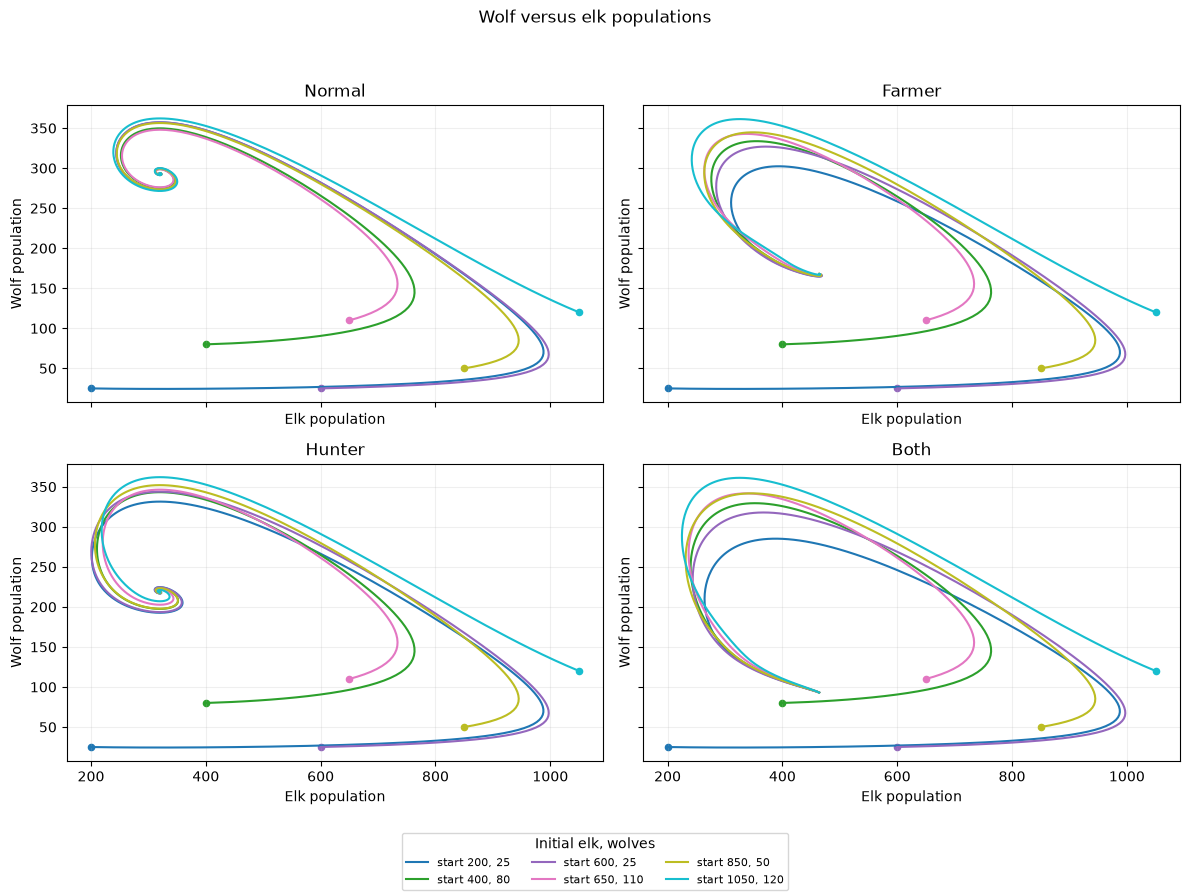

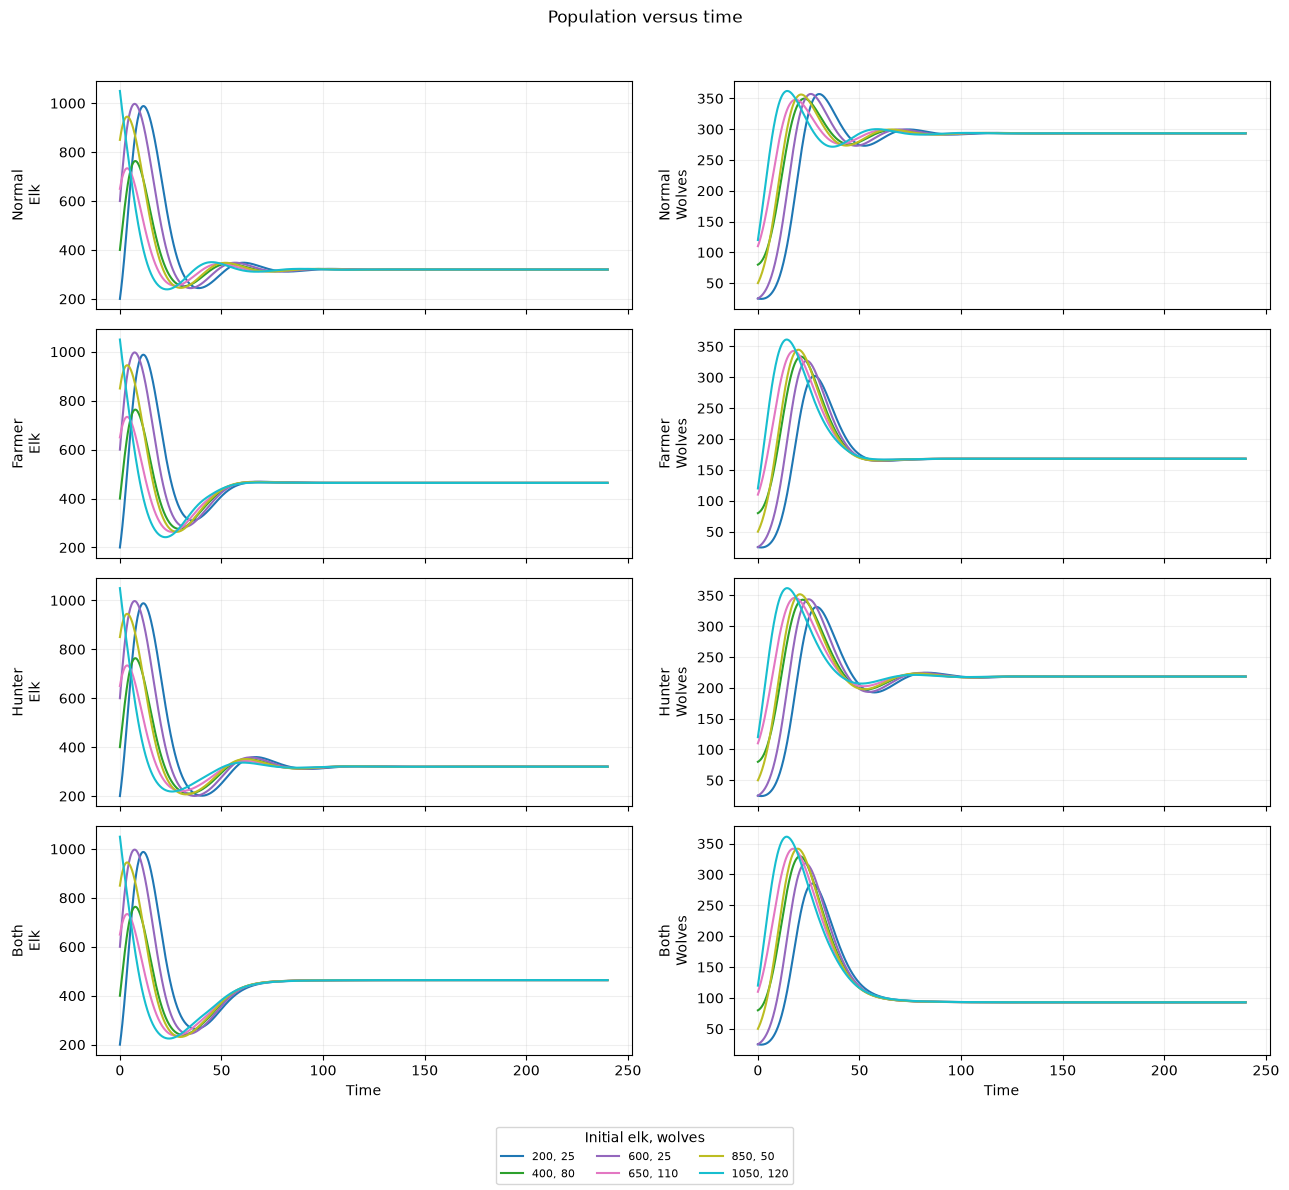

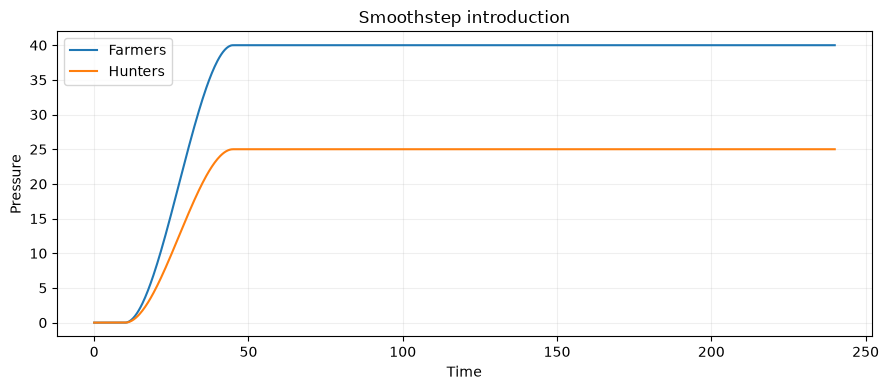

In [3]:
scenarios = ("normal", "farmer", "hunter", "both")
colors = plt.cm.tab10(np.linspace(0, 1, len(INITIAL_POPULATIONS)))
results = {
    (scenario, initial): simulate(initial, scenario)
    for scenario in scenarios
    for initial in INITIAL_POPULATIONS
}

# Wolf-versus-elk trajectories, grouped by scenario.
phase_fig, phase_axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, scenario in zip(phase_axes.flat, scenarios):
    for color, initial in zip(colors, INITIAL_POPULATIONS):
        sol = results[(scenario, initial)]
        ax.plot(sol.y[0], sol.y[1], color=color,
                label=f"start {initial[0]}, {initial[1]}")
        ax.scatter(sol.y[0, 0], sol.y[1, 0], color=color, s=20)
    ax.set(title=scenario.title(), xlabel="Elk population", ylabel="Wolf population")
    ax.grid(alpha=0.2)
handles, labels = phase_axes.flat[0].get_legend_handles_labels()
phase_fig.legend(handles, labels, title="Initial elk, wolves",
                 loc="lower center", ncol=3, fontsize=8)
phase_fig.suptitle("Wolf versus elk populations")
phase_fig.tight_layout(rect=(0, 0.08, 1, 0.95))

# Elk and wolf populations over time, grouped by scenario.
time_fig, time_axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
for row, scenario in enumerate(scenarios):
    for color, initial in zip(colors, INITIAL_POPULATIONS):
        sol = results[(scenario, initial)]
        time_axes[row, 0].plot(sol.t, sol.y[0], color=color,
                               label=f"{initial[0]}, {initial[1]}")
        time_axes[row, 1].plot(sol.t, sol.y[1], color=color,
                               label=f"{initial[0]}, {initial[1]}")
    time_axes[row, 0].set_ylabel(f"{scenario.title()}\nElk")
    time_axes[row, 1].set_ylabel(f"{scenario.title()}\nWolves")
    for ax in time_axes[row]:
        ax.grid(alpha=0.2)
time_axes[-1, 0].set_xlabel("Time")
time_axes[-1, 1].set_xlabel("Time")
handles, labels = time_axes[0, 0].get_legend_handles_labels()
time_fig.legend(handles, labels, title="Initial elk, wolves",
                loc="lower center", ncol=3, fontsize=8)
time_fig.suptitle("Population versus time")
time_fig.tight_layout(rect=(0, 0.06, 1, 0.96))

# Show how the selected introduction schedule changes farmer and hunter pressure.
times = np.linspace(0, TIME_END, TIME_POINTS)
level = introduction(times)
pressure_fig, pressure_ax = plt.subplots(figsize=(9, 4))
pressure_ax.plot(times, MAX_FARMERS * level, label="Farmers")
pressure_ax.plot(times, MAX_HUNTERS * level, label="Hunters")
pressure_ax.set(xlabel="Time", ylabel="Pressure",
                title=f"{INTRODUCTION_SHAPE.title()} introduction")
pressure_ax.grid(alpha=0.2)
pressure_ax.legend()
pressure_fig.tight_layout()

plt.show()

plt.show()
